**Proyecto 1: Análisis de señales ECG y detección de arritmias**

**Integrantes:** Paula García · Valentina Morales


**Fecha de entrega:**

---

 **1.1 Diagramas de flujo**

Artículo 1. Gadaleta et al. (2023), *npj Digital Medicine*
Predicción de fibrilación auricular a 2 semanas a partir de ECG de una derivación sin arritmias.

![Diagrama artículo 1](diagrama_articulo1.png)

Artículo 2. Zheng et al. (2020), *Scientific Reports*
Clasificación multietapa de arritmias (base Chapman).

![Diagrama artículo 2](diagrama_articulo2.png)

Artículo 3. Liu et al. (2024), *Heliyon*
Clasificación de arritmias con CNN sobre ECG de una derivación, sin detección del QRS.

![Diagrama artículo 3](diagrama_articulo3.png)

---

**1.2 Explicación de las metodologías con nuestras palabras**

**Artículo 1:** La fibrilación auricular es una arritmia en la que las aurículas laten de manera descontrolada. Es difícil de detectar con métodos tradicionales porque puede aparecer y desaparecer de forma súbita e impredecible, por lo que ni un electrocardiograma de diez segundos, ni siquiera un Holter de veinticuatro horas garantizan capturar un episodio, ya que no se sabe cuándo va a ocurrir.

Frente a ese problema, el artículo propone un modelo que recibe ventanas de ECG de diez minutos y predice si la persona podría tener un episodio de fibrilación auricular en las siguientes dos semanas, aunque el ECG analizado no muestre ningún signo de la arritmia. Se usan ventanas de diez minutos por un tema de costo computacional, ya que es mucho más manejable para los modelos procesar esa cantidad de datos que la señal completa de veinticuatro horas de una sola vez.

El primer modelo se entrena con cada ventana de forma independiente y extrae ciento veintiocho parámetros propios de la morfología de la señal, que no corresponden a fórmulas definidas por médicos o estadísticos, sino a patrones que el modelo considera relevantes durante su entrenamiento. Además, para cada ventana también se calculan estadísticos ya conocidos, como la variabilidad del ritmo cardíaco y la cantidad de latidos ectópicos. En total, un día se divide en ciento cuarenta y cuatro ventanas, y por cada una se obtiene un paquete que combina los ciento veintiocho parámetros de la red con los estadísticos tradicionales. Esa secuencia completa de ventanas se le pasa al segundo modelo, que la procesa en orden temporal y decide qué tan en riesgo está la persona de sufrir fibrilación auricular.
Para evaluar el desempeño se usa el *AUC*, un índice que indica qué tan bien distingue el modelo entre una persona que va a tener fibrilación auricular y una que no, y que va de 0.5, equivalente al azar, a 1, que sería un modelo perfecto.
Usando solamente edad y sexo, el *AUC* es de 0.67; agregando la variabilidad del ritmo cardíaco sube a 0.74; y utilizando todos los datos disponibles, incluyendo los ciento veintiocho parámetros de la red neuronal y los estadísticos tradicionales, llega a 0.80.

Sin embargo, de la cohorte estudiada solo el 4.3% de las personas tuvo realmente un episodio de fibrilación auricular durante esas dos semanas. Esa baja prevalencia hace que, aunque el modelo tenga una sensibilidad del 0.80, su precisión sea naturalmente baja, de apenas 0.09, lo que significa que se generan muchos falsos positivos: de cada cien alertas de riesgo alto, solo nueve corresponden a casos reales de fibrilación auricular.

**Artículo 2:** Las arritmias cardíacas se diagnostican con un electrocardiograma, pero interpretarlo depende de que un cardiólogo lo revise, lo que toma tiempo y limita la detección a gran escala. El artículo propone un método automático que, a partir de un ECG, clasifica el ritmo que el paciente tiene en ese momento (no predice lo que pueda pasar en el futuro) en cuatro grupos: bradicardia sinusal, fibrilación o aleteo auricular, taquicardias supraventriculares y ritmo sinusal.

Se usó una base de datos de más de cuarenta mil pacientes, con ECG de doce derivaciones de diez segundos, donde los ritmos fueron diagnosticados por cardiólogos. Originalmente había once ritmos distintos, y se agruparon en cuatro según su relevancia clínica, porque algunos tenían muy pocos casos para entrenar un modelo.

Primero se limpia la señal en tres pasos: un filtro pasa-bajas que elimina el ruido de alta frecuencia, un método llamado LOESS robusto que corrige el movimiento lento de la línea base, por debajo de 0.5 Hz, y un tercer método, Non Local Means, que quita el ruido que queda. Después se detectan los picos y valles de la señal, que se clasifican en complejos QRS, picos que no son QRS y valles, y de cada uno se miden la altura, el ancho y la prominencia. También se comparan estos elementos por pares y se calculan razones respecto al tiempo entre ellos.

El problema es que cada paciente tiene un número distinto de latidos, y por lo tanto de picos y valles, pero el modelo necesita que todos los pacientes tengan la misma cantidad de datos. Por eso cada variable se resume en un histograma de cien intervalos, que cuenta cuántas veces aparece cada rango de valores. Se usa un histograma y no un promedio porque el promedio pierde la forma de la distribución: dos pacientes pueden tener el mismo valor promedio pero comportamientos muy distintos, y el histograma sí lo captura.

Con esos datos se compararon diecinueve algoritmos de clasificación combinados con cinco estrategias, ajustando sus parámetros y validando con validación cruzada de diez partes. Los mejores fueron los árboles con gradient boosting. En el boosting los árboles se construyen uno tras otro, y cada uno intenta corregir los errores del anterior, a diferencia del bagging, donde los árboles se entrenan de forma independiente y se promedian. Con este método el *F1-score* fue de 0.988 en pacientes sin otras condiciones cardíacas y de 0.97 en pacientes que sí las tenían. El F1 combina la precisión y la sensibilidad, por lo que un valor alto indica que el modelo clasifica bien sin sacrificar ninguna de las dos.

También se probó el método en la base MIT-BIH y se obtuvo un *F1-score* de 0.992, aunque ahí la tarea fue clasificar latidos individuales y no ritmos, por lo que no es una validación del mismo problema. Otra limitación es que el artículo no aclara en cuál de los cuatro grupos queda la taquicardia sinusal, que representa más del 15% de los pacientes, y que la afirmación de desempeño comparable al de cardiólogos no se midió directamente contra ellos.

**Artículo 3:** Muchos métodos de clasificación de arritmias dependen de detectar primero el complejo QRS, para medir intervalos entre latidos y calcular rasgos a partir de ahí. El problema es que esa detección falla fácilmente cuando la señal tiene ruido o movimiento, que es lo que pasa con los dispositivos portátiles. El artículo propone un método que clasifica arritmias directamente sobre la señal, sin detectar el QRS, usando una red neuronal convolucional.

Se usan señales de una sola derivación de tres bases de datos de PhysioNet, con nueve ritmos cardíacos: ritmo sinusal normal, fibrilación auricular, aleteo auricular, Wolff-Parkinson-White, bloqueo Mobitz II, bradicardia sinusal, taquicardia ventricular, fibrilación ventricular y aleteo ventricular. Como las bases venían con frecuencias de muestreo distintas, todas se llevaron a 250 Hz. Luego las señales se cortaron en segmentos de cinco y de diez segundos, y para aumentar el número de muestras se usaron ventanas superpuestas, es decir, segmentos que comparten una parte de la señal con el siguiente.

La red recibe el segmento completo y tiene cuatro capas convolucionales, con max pooling entre ellas. La primera capa detecta patrones simples de la señal, y las siguientes los van combinando en estructuras cada vez más complejas. El max pooling reduce el tamaño de lo que se procesa y conserva lo más relevante. Al final, capas totalmente conectadas y una función softmax dan la probabilidad de que el segmento corresponda a cada uno de los nueve ritmos.

Con segmentos de cinco segundos la exactitud fue de 96.51%, y con diez segundos de 98.1%. Además, el modelo de cinco segundos se probó con una base distinta, CUDB, que no se usó para entrenar y en la que se emplearon los ritmos completos sin solapamiento, y ahí la exactitud bajó a 91.6%. Una de las confusiones más frecuentes fue clasificar fibrilación auricular como aleteo auricular.

Hay varias limitaciones. Con ventanas superpuestas puede haber fuga de datos: si una ventana queda en entrenamiento y otra, que comparte parte de la misma señal, queda en validación, el modelo estaría evaluándose con algo que ya vio casi igual, lo que inflaría la exactitud interna. El artículo no aclara cómo se dividieron los datos, así que esto es una posibilidad y no algo confirmado. Eso encaja con que la exactitud baje en la prueba externa.

---

**2.1 Carga y revisión general de los datos**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RUTA_DIAGNOSTICS = Path("Diagnostics.xlsx")  
RUTA_SENALES = Path("ECGDataDenoised")     

df = pd.read_excel(RUTA_DIAGNOSTICS)

print(df.shape)
display(df.head())
display(df.dtypes)

# faltantes y duplicados
print(df.isna().sum().sum(), "faltantes;", df.duplicated().sum(), "filas duplicadas;",
      df["FileName"].duplicated().sum(), "FileName repetidos")

# resumen numérico y categórico
display(df.describe().T)
for c in ["Rhythm", "Gender"]:
    display(df[c].value_counts())
print("Beat:", df["Beat"].nunique(), "combinaciones;", (df["Beat"] == "NONE").mean().round(3), "es NONE")

# chequeos de rango
print("menores de 18:", (df.PatientAge < 18).sum())
print("QRS < 40 ms:", (df.QRSDuration < 40).sum())
print("AtrialRate == 0:", (df.AtrialRate == 0).sum())

(10646, 16)


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


FileName           object
Rhythm             object
Beat               object
PatientAge          int64
Gender             object
VentricularRate     int64
AtrialRate          int64
QRSDuration         int64
QTInterval          int64
QTCorrected         int64
RAxis               int64
TAxis               int64
QRSCount            int64
QOnset              int64
QOffset             int64
TOffset             int64
dtype: object

0 faltantes; 0 filas duplicadas; 0 FileName repetidos


,count,mean,std,min,25%,50%,75%,max
PatientAge,10646.0,59.186831,18.030019,4.0,49.0,62.0,72.0,98.0
VentricularRate,10646.0,84.136107,34.455349,34.0,57.0,73.0,104.0,263.0
AtrialRate,10646.0,92.577870,60.093940,0.0,57.0,72.0,106.0,535.0
QRSDuration,10646.0,90.989292,17.479540,18.0,80.0,88.0,98.0,256.0
QTInterval,10646.0,384.150855,59.226289,114.0,344.0,390.0,426.0,736.0
QTCorrected,10646.0,434.154048,39.354182,219.0,408.0,430.0,456.0,760.0
RAxis,10646.0,39.620609,41.212648,-89.0,14.0,46.0,68.0,270.0
TAxis,10646.0,44.637704,57.478092,-89.0,19.0,42.0,62.0,270.0
QRSCount,10646.0,13.839470,5.676339,5.0,9.0,12.0,17.0,40.0
QOnset,10646.0,219.260567,6.410413,159.0,216.0,219.0,224.0,240.0


Rhythm
SB       3889
SR       1826
AFIB     1780
ST       1568
SVT       587
AF        445
SA        399
AT        121
AVNRT      16
AVRT        8
SAAWR       7
Name: count, dtype: int64

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64

Beat: 742 combinaciones; 0.509 es NONE
menores de 18: 265
QRS < 40 ms: 1
AtrialRate == 0: 12


La base `Diagnostics.xlsx` contiene 10.646 registros, uno por paciente, y 16 variables: el nombre del archivo de la señal (`FileName`), el ritmo cardíaco (`Rhythm`), otras condiciones del ECG (`Beat`), la edad, el sexo y 11 mediciones del electrocardiograma, entre ellas las frecuencias ventricular y auricular, la duración del QRS, los intervalos QT y los ejes eléctricos. No hay valores faltantes ni registros duplicados, y cada `FileName` es único, lo que permite emparejar cada fila con su señal.

Hay 11 ritmos: SB (bradicardia sinusal), SR (ritmo sinusal), ST (taquicardia sinusal), AFIB (fibrilación auricular), AF (aleteo auricular), SA (irregularidad sinusal), SVT (taquicardia supraventricular), AT (taquicardia auricular), AVNRT, AVRT y SAAWR (marcapasos auricular errante).

La edad de los pacientes tiene una media de 59 años (desviación estándar de 18), una mediana de 62 y va de 4 a 98 años. El 56% son hombres (5.956) y el 44% mujeres (4.690). La frecuencia ventricular media es de 84 latidos por minuto y la duración media del QRS es de 91 ms. El ritmo más frecuente es la bradicardia sinusal, y tres ritmos (SB, SR y AFIB) concentran cerca del 70% de los registros, mientras que AVNRT, AVRT y SAAWR tienen menos de 20 registros cada uno.

Como observaciones sobre la calidad de los datos: hay 265 pacientes menores de 18 años, un registro con una duración del QRS de 18 ms, que es fisiológicamente imposible y probablemente un error de medición, y la columna `Beat` contiene 742 combinaciones de condiciones adicionales, de las cuales el 51% corresponde a `NONE`. Estos aspectos se tendrán en cuenta en los análisis siguientes.

---

**2.2 ¿Qué tipo de arritmias son más prevalentes?**

,n,%
Rhythm,,
SB,3889,36.53
SR,1826,17.15
AFIB,1780,16.72
ST,1568,14.73
SVT,587,5.51
AF,445,4.18
SA,399,3.75
AT,121,1.14
AVNRT,16,0.15


,n,% de arritmias
Rhythm,,
SB,3889,44.09
AFIB,1780,20.18
ST,1568,17.78
SVT,587,6.66
AF,445,5.05
SA,399,4.52
AT,121,1.37
AVNRT,16,0.18
AVRT,8,0.09


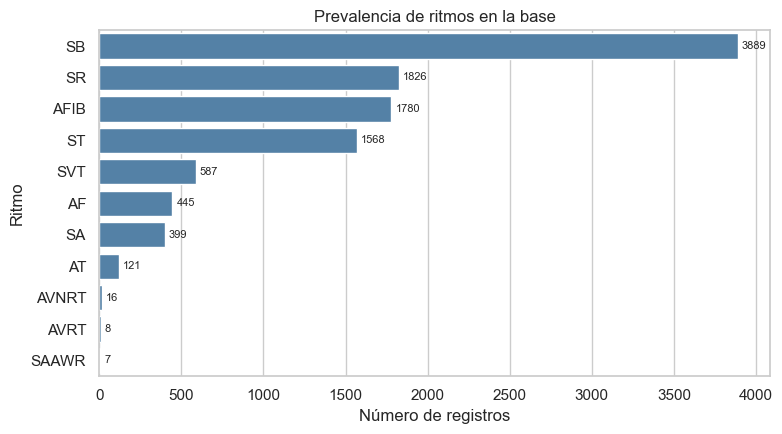

In [ ]:
# Prevalencia de los 11 ritmos
prev = df["Rhythm"].value_counts().to_frame("n")
prev["%"] = (100 * prev["n"] / len(df)).round(2)
display(prev)

# Sin SR (ritmo normal): solo arritmias
arr = df[df["Rhythm"] != "SR"]
prev_arr = arr["Rhythm"].value_counts().to_frame("n")
prev_arr["% de arritmias"] = (100 * prev_arr["n"] / len(arr)).round(2)
display(prev_arr)

# Gráfico
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="Rhythm", order=prev.index, color="steelblue", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2),
                va="center", ha="left", fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("Número de registros")
ax.set_ylabel("Ritmo")
ax.set_title("Prevalencia de ritmos en la base")
plt.tight_layout()
plt.show()

El ritmo más frecuente en la base es la bradicardia sinusal (SB), con 3.889 registros (36,5% del total). Le siguen el ritmo sinusal normal (SR, 17,2%), la fibrilación auricular (AFIB, 16,7%) y la taquicardia sinusal (ST, 14,7%). Estos cuatro ritmos concentran el 85% de la base. Los demás son menos frecuentes: la taquicardia supraventricular (SVT) representa el 5,5%, el aleteo auricular (AF) el 4,2% y la irregularidad sinusal (SA) el 3,8%, mientras que AT, AVNRT, AVRT y SAAWR están por debajo del 1,2%.

Como SR es el ritmo normal y no una arritmia, al excluirlo (8.820 registros) las arritmias más prevalentes son la bradicardia sinusal (44,1%), la fibrilación auricular (20,2%) y la taquicardia sinusal (17,8%).

---

**2.3 ¿Hay arritmias más prevalentes para un género específico?**


Gender,FEMALE,MALE,total,% hombres,% mujeres
Rhythm,,,,,
SB,1408,2481,3889,63.8,36.2
SR,1024,802,1826,43.9,56.1
AFIB,739,1041,1780,58.5,41.5
ST,769,799,1568,51.0,49.0
SVT,308,279,587,47.5,52.5
AF,188,257,445,57.8,42.2
SA,176,223,399,55.9,44.1
AT,57,64,121,52.9,47.1
AVNRT,12,4,16,25.0,75.0


% de hombres en toda la base: 55.9%


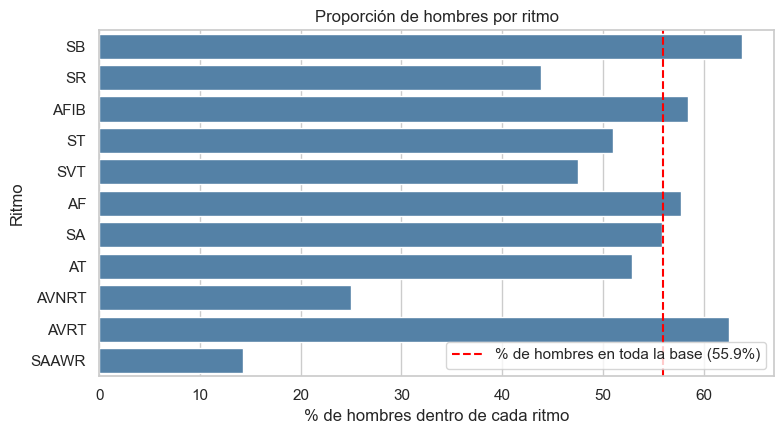

In [ ]:
# Tabla ritmo x sexo
orden = df["Rhythm"].value_counts().index
ct = pd.crosstab(df["Rhythm"], df["Gender"]).loc[orden, ["FEMALE", "MALE"]]
ct["total"] = ct.sum(axis=1)
ct["% hombres"] = (100 * ct["MALE"] / ct["total"]).round(1)
ct["% mujeres"] = (100 * ct["FEMALE"] / ct["total"]).round(1)
display(ct)

base_h = 100 * (df["Gender"] == "MALE").mean()
print(f"% de hombres en toda la base: {base_h:.1f}%")

# Gráfico: % de hombres por ritmo
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=ct.reset_index(), y="Rhythm", x="% hombres", order=orden, color="steelblue", ax=ax)
ax.axvline(base_h, color="red", linestyle="--", label=f"% de hombres en toda la base ({base_h:.1f}%)")
ax.set_xlabel("% de hombres dentro de cada ritmo")
ax.set_ylabel("Ritmo")
ax.set_title("Proporción de hombres por ritmo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

El 55,9% de los registros de la base de datos corresponde a hombres, por lo que se compara la proporción de hombres de cada ritmo contra ese valor. 

La bradicardia sinusal es más frecuente en hombres (63,8%). En mujeres son más frecuentes el ritmo sinusal normal (56,1% de mujeres), la taquicardia supraventricular (52,5%) y, en menor medida, la taquicardia sinusal (49,0%). La fibrilación auricular (58,5% de hombres), el aleteo auricular y la irregularidad sinusal se mantienen cerca del valor de la base. En AVNRT, AVRT y SAAWR hay muy pocos registros (16, 8 y 7) para concluir algo.

---

**2.4 ¿Hay arritmias más prevalentes para una edad?**
